# 03 · Station choice, network load and queues

**Question.** If drivers choose among today's rapid sites by travel time, price, power and size, where does the demand land, and where do queues form at the peak hour?

**Method.** Multinomial logit allocation (`chargescape.models.choice`, literature-informed parameters) of rapid-type demand (destination + PHV, P50) from every hex to rapid sites within 20 minutes on the OSM drive network; Erlang-C M/M/c queue per site with 38-minute service (Dundee median). Supply: Open Charge Map ∪ OpenStreetMap ∪ NCR 2021 rapid sites, de-duplicated within 50 m; ports of mapped sites are scaled per borough so that totals match DfT's official 50 kW+ counts (the factor is stored per site).

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from chargescape.utils.paths import PROCESSED, INTERIM, FIGURES, TABLES, DOCS
from chargescape.utils.io import read_gdf
from chargescape.viz.figures import hex_map, save, barh, boroughs
from chargescape.utils.reference import dft_la, charging_sites
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
feats = read_gdf(PROCESSED / "hex_features_r8.small.parquet")
print(feats.shape)

(2374, 81)


In [2]:
from chargescape.models.choice import ChoiceParams
print(ChoiceParams().__dict__)
sites = pd.read_parquet(PROCESSED / "rapid_sites_load_2026.small.parquet")
svc = pd.read_parquet(PROCESSED / "hex_service_2026.small.parquet")
print(f"{len(sites)} rapid sites, {sites.ports.sum():,} ports after calibration (known ports {sites.ports_known.sum():,.0f}, median scale ×{sites.port_scale.median():.1f})")
sites[["sessions_day", "kwh_day", "utilisation_24h", "utilisation_peak", "p_wait", "mean_wait_min"]].describe().round(2).T

{'b_tt': -0.25, 'b_price': -0.04, 'b_power': 0.6, 'b_wait': -0.08, 'b_ports': 0.3, 'outside_utility': None, 'max_tt_min': 20.0}
632 rapid sites, 2,860 ports after calibration (known ports 1,730, median scale ×1.6)


,count,mean,std,min,25%,50%,75%,max
sessions_day,632.0,52.42,40.32,3.46,28.37,41.71,65.69,300.58
kwh_day,632.0,891.17,685.49,58.76,482.31,709.12,1116.67,5109.87
utilisation_24h,632.0,0.20,0.16,0.01,0.09,0.15,0.25,1.05
utilisation_peak,632.0,0.92,0.68,0.09,0.45,0.74,1.19,4.65
p_wait,632.0,0.55,0.40,0.00,0.13,0.59,1.00,1.00
mean_wait_min,632.0,inf,NaN,0.00,2.33,35.01,NaN,inf


## 1. Where load concentrates and where queues form

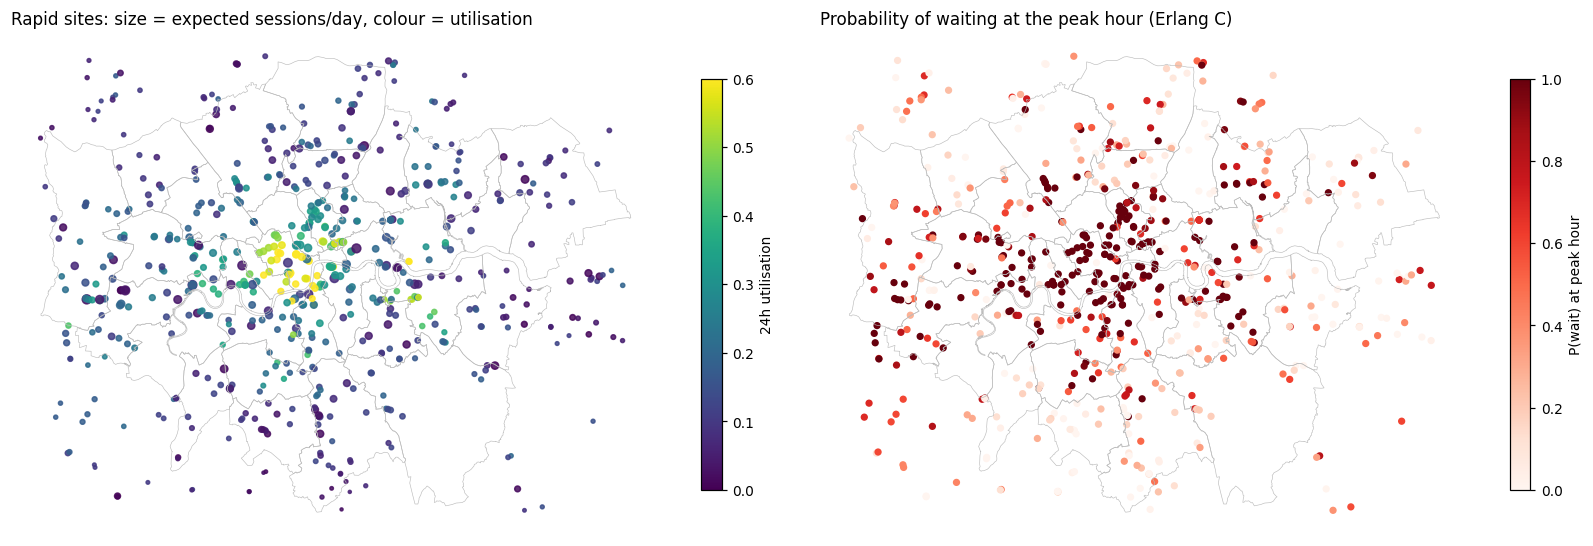

sites with P(wait) > 0.5 at peak: 348 of 632; median expected wait 7.0 min


,borough,operator,power_kw,ports,sessions_day,utilisation_24h,p_wait,mean_wait_min
131,Hillingdon,Tesla (including non-tesla),250.0,27,300.58,0.03,0.02,0.07
139,Hounslow,Tesla (Tesla-only charging),250.0,25,274.64,0.03,0.02,0.08
568,Tower Hamlets,Smart Charge by Sainsbury's (UK),150.0,37,271.43,0.03,0.00,0.00
288,Hounslow,BP Pulse (UK),300.0,9,256.23,0.07,1.00,inf
307,Hammersmith and Fulham,Tesla (Tesla-only charging),150.0,30,249.96,0.04,0.00,0.00
265,Southwark,MFG EV Power,150.0,14,237.12,0.08,0.85,67.05
277,Westminster,BP Pulse (UK),50.0,34,228.25,0.10,0.00,0.00
164,Greenwich,FastNed,300.0,8,205.40,0.06,1.00,inf
578,Enfield,Tesla (including non-tesla),250.0,26,198.25,0.02,0.00,0.00
35,Lambeth,Smart Charge by Sainsbury's (UK),150.0,11,191.26,0.08,0.97,373.21


In [3]:
s = gpd.GeoDataFrame(sites, geometry=gpd.points_from_xy(sites.lon, sites.lat), crs=4326).to_crs(27700)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
boroughs().boundary.plot(ax=axes[0], color="#bbbbbb", linewidth=0.4)
s.plot(ax=axes[0], markersize=np.sqrt(s.sessions_day) * 2, column="utilisation_24h", cmap="viridis", vmin=0, vmax=0.6, alpha=0.85, legend=True, legend_kwds={"label": "24h utilisation", "shrink": 0.6})
axes[0].set_axis_off(); axes[0].set_title("Rapid sites: size = expected sessions/day, colour = utilisation", loc="left")
boroughs().boundary.plot(ax=axes[1], color="#bbbbbb", linewidth=0.4)
s.plot(ax=axes[1], markersize=14, column="p_wait", cmap="Reds", vmin=0, vmax=1, legend=True, legend_kwds={"label": "P(wait) at peak hour", "shrink": 0.6})
axes[1].set_axis_off(); axes[1].set_title("Probability of waiting at the peak hour (Erlang C)", loc="left")
plt.tight_layout(); save(fig, "03_site_load_queues.png"); plt.show()
print(f"sites with P(wait) > 0.5 at peak: {(sites.p_wait > 0.5).sum()} of {len(sites)}; median expected wait {sites.mean_wait_min.replace(np.inf, np.nan).median():.1f} min")
sites.sort_values("sessions_day", ascending=False)[["borough", "operator", "power_kw", "ports", "sessions_day", "utilisation_24h", "p_wait", "mean_wait_min"]].head(10).round(2)

## 2. What drivers experience, by hex

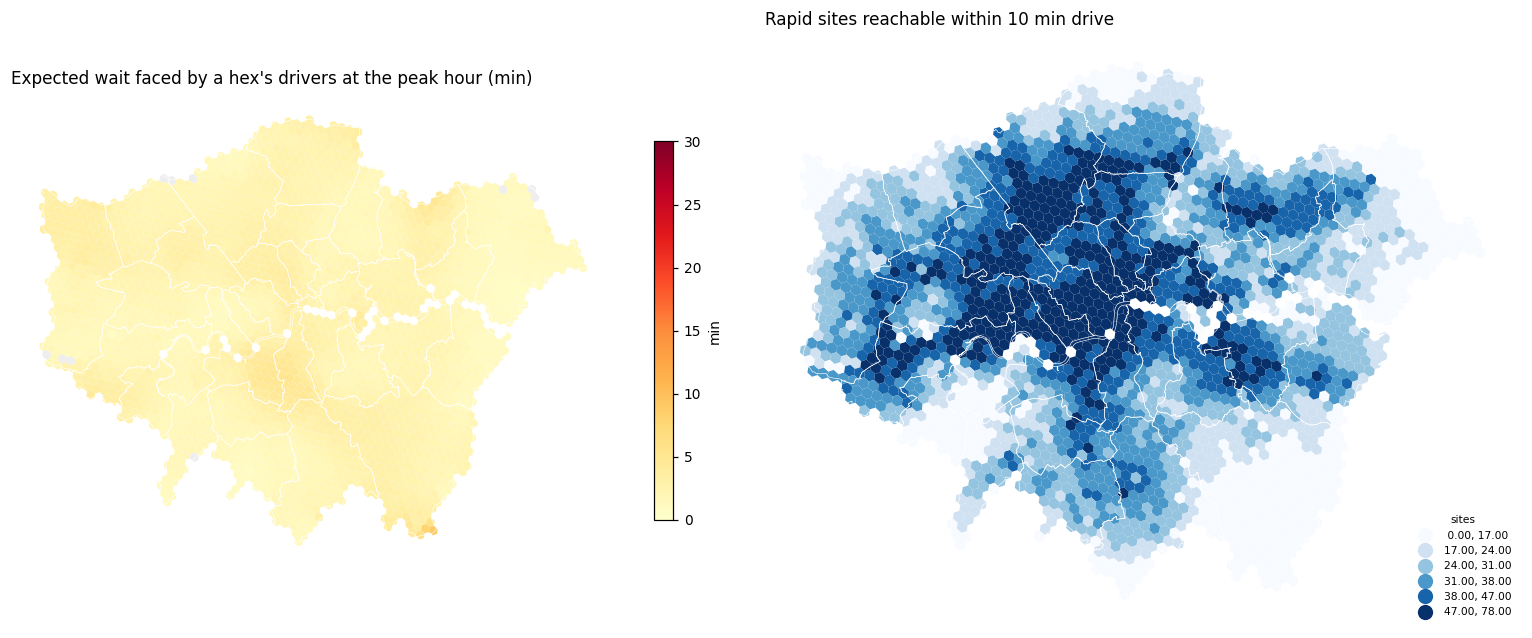

In [4]:
g = feats.merge(svc, on="h3", how="left")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
hex_map(g, "expected_wait_min", "Expected wait faced by a hex's drivers at the peak hour (min)", cmap="YlOrRd", vmin=0, vmax=30, ax=axes[0], legend_label="min")
hex_map(g, "n_rapid_within_10min", "Rapid sites reachable within 10 min drive", cmap="Blues", scheme="quantiles", k=6, ax=axes[1], legend_label="sites")
plt.tight_layout(); save(fig, "03_hex_experience.png"); plt.show()

## 3. Incremental demand vs cannibalisation for a candidate hub

In [5]:
from chargescape.models.allocation_pipeline import candidate_increment
inc, cand = candidate_increment()
print(f"candidate hub: hex {cand['h3']} in {cand['borough']} (largest unmet or queue-constrained rapid demand)")
inc.round(2)

candidate hub: hex 88195d371bfffff in Hillingdon (largest unmet or queue-constrained rapid demand)


,power_kw,ports,captured,new,cannibalised,cannibalisation_share
0,50,2,44.29,15.99,28.29,0.64
1,150,4,93.64,28.01,65.62,0.70
2,150,8,111.52,31.51,80.01,0.72
3,300,8,157.55,39.32,118.23,0.75


**Reading.** Even at the hex with the largest unmet demand, most of a new hub's sessions are taken from existing sites; bigger and faster hubs capture more in total but also cannibalise a larger share. This is the number an investor or partner needs next to the headline "expected sessions", and it is exactly what a pure gap map cannot show. Choice parameters are literature-informed; notebook 04 reports how the siting result moves when they change.